# Evaluate hazard indicators for different combinations of their parameters

In [1]:
import pathlib

import matplotlib.pyplot as plt
import numpy
import xarray
import xclim

from framework.packages.xclim import (
    get_variable_parameters,
    print_variable_parameters,
    set_variable_parameters
)
import plots
import thesis

xarray.set_options(keep_attrs=True)

In [2]:
location = "torino"  # Select the spatial center of the analysis, cf. thesis.coords keys.

dir_data = thesis.dir_data / location / "adjusted"

In [3]:
scenario = thesis.scenario[0]  # Start by analysing only one scenario at time.

m = "EC-Earth3"  # Only model EC-Earth3 is used for the midterm discussion.

ds_data = xarray.open_mfdataset(
    (dir_data / f"historical_{m}.nc", dir_data / f"{scenario}_{m}.nc"),
    chunks={"latitude": 1, "longitude": 1, "time": -1},
    combine="nested",
    combine_attrs="drop_conflicts"
)

In [4]:
drivers = {}
indicators = {}
for d in thesis.drivers:
    _module = xclim.core.indicator.build_indicator_module_from_yaml(pathlib.Path(f"{d}.yml"))
    drivers[d] = dict(_module.iter_indicators())
    indicators.update(drivers[d])

## Define intervals of parameters

For each indicator a set of values should be defined such that they are meaningful for the analysis. Ideally these sets would be continous, but for limitations intrinsic to the analysis tools, only a finite and small number of values can be considered. Nevertheless, they are still called intervals to maintain generality.

In [5]:
intervals = {}  # Create structure for storing intervals.
for i in indicators:
    intervals[i] = get_variable_parameters(indicators[i])

Boundaries of these intervals are arbitrary. In principle they should be sufficiently extreme to allow the indicator to show interesting information on the climate of past and future. This information is not known a priori, hence depending on the quantity each parameter refers to, an estimation must be made.

In general climate variables depend also on spatial dimensions. The procedure to estimate values for parameter intervals neglects this dependence and all data are gathered in the same sample.

For parameters related to climate variables (e.g. thresholds) for which data is available from models, the quantile function of data is first plotted to acknowledge the shape of the cumulative probability function, then values are chosen with the aim to sample the probability distribution uniformly. The density of points may be increased where needed to describe better the shape of the distribution.

For parameters not related directly to a climate variable (e.g. window size for moving average), some heuristic is applied and explained case by case.

In [6]:
percentiles = numpy.arange(0, 101, 1) / 100

ds_data_sample = ds_data.stack(dim={"sample": [...]}, create_index=False).chunk({"sample": -1})
ds_percentiles = ds_data_sample.quantile(percentiles, dim="sample", method="linear")

### Heat wave

The following are indicators chosen for the heat wave driver and the list of their parameters.

In [7]:
for i in drivers["heat_wave"].values():
    print_variable_parameters(i)
    print()

heat_wave_frequency
Number of heat waves. A heat wave occurs when daily minimum and maximum temperatures exceed given thresholds for a number of days.
- thresh_tasmin: The minimum temperature threshold needed to trigger a heatwave event.
- thresh_tasmax: The maximum temperature threshold needed to trigger a heatwave event.
- window: Minimum number of days with temperatures above thresholds to qualify as a heatwave.

heat_wave_max_length
Total duration of heat waves. A heat wave occurs when daily minimum and maximum temperatures exceed given thresholds for a number of days.
- thresh_tasmin: The minimum temperature threshold needed to trigger a heatwave event.
- thresh_tasmax: The maximum temperature threshold needed to trigger a heatwave event.
- window: Minimum number of days with temperatures above thresholds to qualify as a heatwave.

heat_wave_total_length
Maximum length of heat waves. A heat wave occurs when daily minimum and maximum temperatures exceed given thresholds for a numbe

The parameters the same quantities, hence same intervals are used.

Intervals for `thresh_tasmin` and `thresh_tasmax` are quantiles of distribution of `tasmin` and `tasmax`. First plot the quantile function considering the percentilesorresponding to a frequency multiple of $0.01$.

Text(0, 0.5, 'Temperature [K]')

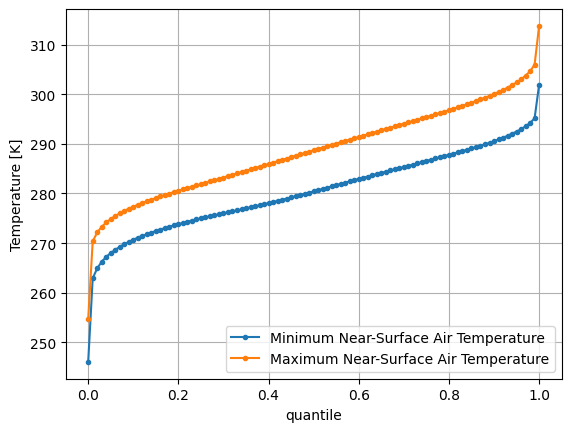

In [8]:
_plot = plots.data_vars_1d(ds_percentiles, data_vars=("tasmin", "tasmax"), label_attrs_key="long_name", marker='.')
ax = _plot.axes[0]
ax.legend(loc="lower right")
ax.set_ylabel(f"Temperature [{ds_percentiles['tasmin'].attrs['units']}]")

Since the distributions of both values present a steep variation near the extremes, more points are inserted at the boundaries of the intervals. Instead, the number of points around the mean can be small.

A less arbitrary method would be fit a probit distribution and sample an interval, but from a qualitatively analysis of the plots, the quantile function is not symmetric and this skewness should be account for during the sampling.

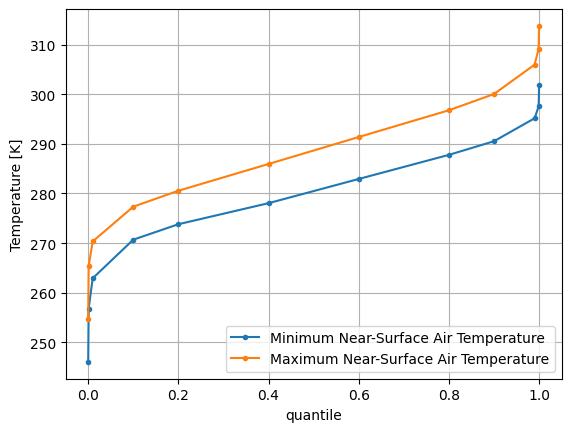

In [9]:
quantiles = numpy.arange(0, 11, 2) / 10
quantiles = numpy.insert(quantiles, 1, (0.001, 0.01, 0.1))
quantiles = numpy.insert(quantiles, -1, (0.9, 0.99, 0.999))
_ds = ds_data_sample[["tasmin", "tasmax"]].quantile(quantiles, dim="sample", method="linear")

_plot = plots.data_vars_1d(_ds, label_attrs_key="long_name", marker='.')
ax = _plot.axes[0]
ax.legend(loc="lower right")
ax.set_ylabel(f"Temperature [{_ds['tasmin'].attrs['units']}]")

# Store intervals.
_ds = _ds.rename({"tasmin": "thresh_tasmin", "tasmax": "thresh_tasmax"})
for i in drivers["heat_wave"].keys():
    set_variable_parameters(intervals[i], _ds.data_vars)

Values for parameter `window` are integers hence the minimum value is 1. This parameter acts as a threshold for the application of the indicator's logic: events which span a number of days less than the window size are not considered. Since indicators are resampled with frequency of one year, meaning that they result in a value for each year of the considered period, the maximum is set at 360 for ease.

Intermediate values of the interval are aligned to the common time units of 360-day calendar (e.g. week, month).

In [10]:
_interval = numpy.arange(1, 8, 1)
_interval = numpy.append(_interval, 7 * numpy.arange(2, 4, 1))
_interval = numpy.append(_interval, 30 * numpy.arange(1, 13, 1))
print(_interval)

# Store intervals in a data structure which contains also the units.
interval_window = xarray.DataArray(data=_interval, name="window")
for i in drivers["heat_wave"].keys():
    set_variable_parameters(intervals[i], {"window": interval_window})

[  1   2   3   4   5   6   7  14  21  30  60  90 120 150 180 210 240 270
 300 330 360]


### Heavy precipitation

The following are indicators chosen for the heavy precipitation driver and the list of their parameters.

In [11]:
for i in drivers["heavy_precipitation"].values():
    print_variable_parameters(i)
    print()

max_n_day_precipitation_amount
Maximum of the moving sum of daily precipitation for a given period.
- window: Window size in days.

wetdays
The number of days with daily precipitation at or above a given threshold.
- thresh: Precipitation value over which a day is considered wet.

cwd
The longest number of consecutive days where daily precipitation is at or above a given threshold.
- thresh: Threshold precipitation on which to base evaluation.



As happened for the heat wave driver, some parameters in these indicators represent the same quantities, hence same intervals are applied. In particular, the interval for `window` is the same as the one chosen for the heat wave driver.

Similarly to `thresh_tasmin` and `thresh_tasmax`, values for parameter `thresh` are chosen considering the corrispondend climate variable, i.e. precipitation flux `pr`.

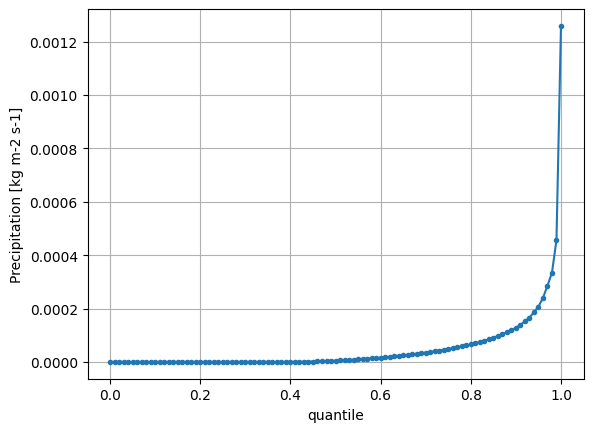

In [12]:
fig = plt.figure()
ds_percentiles["pr"].plot(marker='.')
ax = fig.axes[0].grid(which="both")

The quantile function shows a steep increment at high frequencies in the sample considered. Those are extreme values of precipitation, with low probability and high intensity.
The choice for the interval of `thresh` reflects this behaviour, increasing the density of points near the maximum of `pr`.

[0.     0.2    0.4    0.6    0.8    0.9    0.97   0.99   0.999  0.9999
 1.    ]


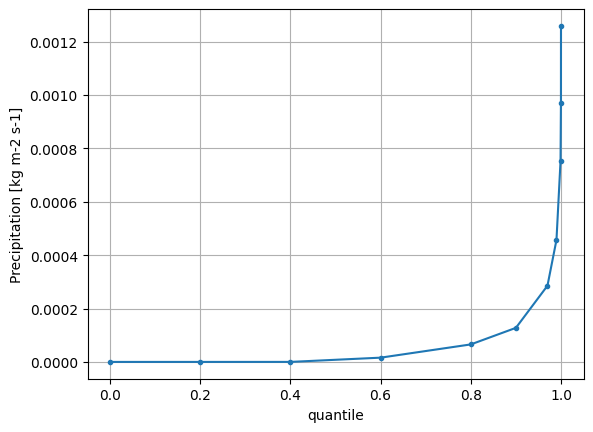

In [13]:
quantiles = numpy.arange(0, 11, 2) / 10
quantiles = numpy.insert(quantiles, -1, (0.9, 0.97, 0.99, 0.999, 0.9999))
print(quantiles)

_da = ds_data_sample["pr"].quantile(quantiles, dim="sample", method="linear")

fig = plt.figure()
_da.plot(marker='.')
ax = fig.axes[0].grid(which="both")

# Store intervals.
_da.name = "thresh"
for i in drivers["heavy_precipitation"].keys():
    set_variable_parameters(intervals[i], {"thresh": _da})
    set_variable_parameters(intervals[i], {"window": interval_window})